## 1. Installation et imports

In [ ]:
!pip install --upgrade --force-reinstall numpy scipy

  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
  Attempting uninstall: scipy
    Found existing installation: scipy 1.18.1
    Uninstalling scipy-1.18.1:
      Successfully uninstalled scipy-1.18.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scipy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1

In [ ]:
!pip install -q -U transformers peft accelerate bitsandbytes sentence-transformers faiss-cpu pandas numpy scipy matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


In [ ]:
# !pip install -q -U transformers peft accelerate bitsandbytes sentence-transformers faiss-cpu pandas numpy scipy matplotlib

In [ ]:
import os, re, json, math, time, gc, random, hashlib, unicodedata, textwrap, platform
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from scipy.stats import binomtest

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 200)
print("python", platform.python_version())

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


python 3.13.16


## 2. Configuration


In [ ]:
STEP1_DIR = Path("outputs/step1_baseline")
STEP2_DIR = Path("outputs/step2_index")
STEP3_DIR = Path("outputs/step3_dataset")
STEP4_DIR = Path("outputs/step4_qlora")
ADAPTER_DIR = STEP4_DIR / "adapter"
PIPELINE_CFG_PATH = Path("outputs/step5_pipeline/pipeline_config.json")
TEST_SET_PATH = Path("test_set_b1.jsonl")
DEV_SET_PATH = Path("dev_retrieval_b1.jsonl")
OUTPUT_DIR = Path("outputs/step6_final"); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
MAX_NEW_TOKENS = 300        # identique aux étapes 1 et 5
JUDGE_MAX_NEW_TOKENS = 40   # identique à l'étape 1
BATCH_SIZE = 4              # identique aux étapes 1 et 5 ; à baisser seulement en cas de « CUDA out of memory » (le noter)
ENFORCE_CITATION = True     # identique à l'étape 5
N_BOOT = 10_000

def load_jsonl(path):
    return [json.loads(l) for l in open(path, encoding="utf-8") if l.strip()]

## 3. Chargement des artefacts des étapes précédentes et contrôles de cohérence



In [ ]:
index_cfg = json.load(open(STEP2_DIR / "index_config.json", encoding="utf-8"))
rag_prompt = json.load(open(STEP3_DIR / "rag_prompt.json", encoding="utf-8"))
dataset_cfg = json.load(open(STEP3_DIR / "dataset_config.json", encoding="utf-8"))
chunks = load_jsonl(STEP2_DIR / "chunks.jsonl")
chunk_by_id = {c["chunk_id"]: c for c in chunks}
K = int(index_cfg["k_final"])
ABSTAIN_MARKER, ABSTAIN_ANSWER = rag_prompt["abstain_marker"], rag_prompt["abstain_answer"]

assert rag_prompt["k_context"] == K, f"k de l'étape 3 ({rag_prompt['k_context']}) ≠ k_final de l'étape 2 ({K}) : refaire l'étape 3 puis l'étape 4"
assert dataset_cfg["step2_config"]["embedder"] == index_cfg["embedder"] and dataset_cfg["step2_config"]["chunking"] == index_cfg["chunking"], \
    "le dataset de l'étape 3 a été construit avec un autre index que celui chargé ici"
assert len(chunks) == index_cfg["n_chunks"], "chunks.jsonl ne correspond pas à index_config.json"
print(f"{len(chunks)} chunks | embedder={index_cfg['embedder']} méthode={index_cfg['method']} k={K} | abstention : « {ABSTAIN_MARKER} »")

239 chunks | embedder=bge-m3 méthode=dense k=5 | abstention : « INFORMATION ABSENTE »


## 4. Retriever

In [ ]:
def norm(s):
    s = unicodedata.normalize("NFKD", s.lower().replace("’", "'"))
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[\s  ]+", " ", s).strip()

STOPWORDS = set("le la les l un une des de du d et ou a au aux en dans par pour sur sous avec sans que qui quoi est sont etre ce cet cette ces se sa son ses "
                "leur leurs ne pas plus il ils elle elles on y c s n qu j m t si comme mais donc car faut faire peut doit quel quelle quels quelles".split())
def tokenize(text):
    toks = re.findall(r"[a-z0-9]+", norm(text))
    return [t[:-1] if len(t) > 3 and t.endswith("s") else t for t in toks if t not in STOPWORDS]

class BM25:
    def __init__(self, docs_tokens, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.docs = [Counter(d) for d in docs_tokens]
        self.len = np.array([len(d) for d in docs_tokens], dtype=float); self.avg = self.len.mean()
        df = Counter(t for d in self.docs for t in d); n = len(docs_tokens)
        self.idf = {t: math.log(1 + (n - f + 0.5) / (f + 0.5)) for t, f in df.items()}
    def scores(self, q_tokens):
        s = np.zeros(len(self.docs))
        for t in set(q_tokens):
            if t in self.idf:
                tf = np.array([d.get(t, 0) for d in self.docs], dtype=float)
                s += self.idf[t] * tf * (self.k1 + 1) / (tf + self.k1 * (1 - self.b + self.b * self.len / self.avg))
        return s

def rrf_fuse(rank_lists, k=60, topn=10):
    sc = defaultdict(float)
    for ranks in rank_lists:
        for pos, j in enumerate(ranks):
            sc[int(j)] += 1.0 / (k + pos + 1)
    return [j for j, _ in sorted(sc.items(), key=lambda x: -x[1])[:topn]]

def cite(c):
    """Chaîne de citation d'un chunk. IDENTIQUE à l'étape 3 (c'est elle qui apparaît dans les prompts d'entraînement)."""
    p = [x for x in c["pages"] if x >= 1]            # la page de présentation du PDF n'a pas de numéro imprimé
    pages = "page non numérotée" if not p else (f"p. {p[0]}" if len(p) == 1 else f"p. {p[0]}-{p[-1]}")
    where = "Présentation du guide" if c["fiche"] == 0 else f"Fiche {c['fiche']} — {c['fiche_title']}"
    return f"{where} — {c['section_label']}, {pages}"

EMBEDDERS = {
    "e5-base":  {"hf_id": "intfloat/multilingual-e5-base",  "q": "query: ", "p": "passage: "},
    "e5-large": {"hf_id": "intfloat/multilingual-e5-large", "q": "query: ", "p": "passage: "},
    "bge-m3":   {"hf_id": "BAAI/bge-m3",                    "q": "",        "p": ""},
}

class STEmbedder:
    """Enveloppe sentence-transformers (même code qu'à l'étape 2). Vecteurs normalisés : produit scalaire = cosinus."""
    def __init__(self, name):
        import torch
        from sentence_transformers import SentenceTransformer
        self.name, self.cfg = name, EMBEDDERS[name]
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.model = SentenceTransformer(self.cfg["hf_id"], device=self.device)
        self.model.max_seq_length = 512
        if self.device == "cuda":
            self.model.half()
    def _enc(self, texts, prefix):
        return self.model.encode([prefix + t for t in texts], batch_size=32, normalize_embeddings=True,
                                 convert_to_numpy=True, show_progress_bar=False).astype("float32")
    def encode_queries(self, texts): return self._enc(texts, self.cfg["q"])

def make_embedder(name):
    return STEmbedder(name)

class Retriever:
    def __init__(self, out_dir, embedder=None):
        import faiss
        out_dir = Path(out_dir)
        self.cfg = json.load(open(out_dir / "index_config.json", encoding="utf-8"))
        self.chunks = load_jsonl(out_dir / "chunks.jsonl")
        self.index = faiss.read_index(str(out_dir / "faiss.index"))
        assert self.index.ntotal == len(self.chunks), "index FAISS et chunks désynchronisés"
        self.embedder = embedder or make_embedder(self.cfg["embedder"])
        self.bm25 = BM25([tokenize(c["embed_text"]) for c in self.chunks]) if self.cfg["method"] == "hybrid" else None
        self.k = self.cfg["k_final"]
    def search_batch(self, questions, k=None):
        k = k or self.k
        n = min(50, len(self.chunks))
        Q = self.embedder.encode_queries(list(questions))
        scores, ids = self.index.search(Q, n)
        out = []
        for qi, (q, s_row, i_row) in enumerate(zip(questions, scores, ids)):
            if self.bm25 is not None:
                bm_rank = np.argsort(-self.bm25.scores(tokenize(q)))[:n]
                order = rrf_fuse([i_row, bm_rank], k=self.cfg["rrf_k"], topn=k)
            else:
                order = [int(j) for j in i_row[:k]]
            cos = dict(zip(i_row.tolist(), s_row.tolist()))
            res = []
            for rank, j in enumerate(order, 1):
                c = self.chunks[j]
                cj = cos[int(j)] if int(j) in cos else float(Q[qi] @ self.index.reconstruct(int(j)))
                res.append({"rank": rank, "chunk": c, "cosine": cj})
            out.append({"question": q, "top1_cosine": float(s_row[0]), "results": res})
        return out

## 5. Prompt RAG (source de vérité : `rag_prompt.json` de l'étape 3)

In [ ]:
def build_messages(question, passages):
    """passages : liste de chunks (dict), dans l'ordre d'affichage [1], [2]…"""
    ctx = "\n\n".join(rag_prompt["passage_template"].format(n=i + 1, citation=cite(c), text=c["text"]) for i, c in enumerate(passages))
    return [{"role": "system", "content": rag_prompt["system"]},
            {"role": "user", "content": rag_prompt["user_template"].format(passages=ctx, question=question)}]

val_records = load_jsonl(STEP3_DIR / "val.jsonl")
n_checked = 0
for rec in val_records:
    q = rec["messages"][1]["content"].split("Question :")[-1].strip()
    rebuilt = build_messages(q, [chunk_by_id[cid] for cid in rec["meta"]["context_chunks"]])
    assert rebuilt == rec["messages"][:2], f"prompt reconstruit ≠ prompt d'entraînement pour {rec['meta']['id']}"
    n_checked += 1
print(f"OK : {n_checked} prompts du val reconstruits à l'identique de l'étape 3.")

OK : 28 prompts du val reconstruits à l'identique de l'étape 3.


## 6. Générateur : Qwen 4-bit + adaptateur LoRA (un seul modèle, B = adaptateur désactivé, C = adaptateur actif)



In [ ]:
class QwenGenerator:
    def __init__(self, model_id=MODEL_ID, adapter_dir=ADAPTER_DIR, max_new_tokens=MAX_NEW_TOKENS, batch_size=BATCH_SIZE):
        import torch, transformers
        from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
        from peft import PeftModel
        if not torch.cuda.is_available():
            raise RuntimeError("Aucun GPU CUDA : bitsandbytes (4-bit) ne fonctionne que sur NVIDIA. Utiliser Colab/Kaggle, ou une autre chaîne d'inférence (llama.cpp / MLX).")
        self.torch, self.max_new_tokens, self.batch_size = torch, max_new_tokens, batch_size
        compute = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=compute)
        self.tok = AutoTokenizer.from_pretrained(model_id, padding_side="left")      # left padding : requis pour la génération par lots
        if self.tok.pad_token is None: self.tok.pad_token = self.tok.eos_token
        try:
            base = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=bnb, dtype=compute, device_map={"": 0})
        except TypeError:                                                           # anciennes versions de transformers
            base = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=bnb, torch_dtype=compute, device_map={"": 0})
        self.model = PeftModel.from_pretrained(base, str(adapter_dir), is_trainable=False)
        self.model.eval()
        self.adapter_sha256 = hashlib.sha256((Path(adapter_dir) / "adapter_model.safetensors").read_bytes()).hexdigest()
        print(f"modèle chargé | dtype de calcul {compute} | VRAM utilisée {torch.cuda.memory_allocated() / 1e9:.1f} Go | adaptateur sha256 {self.adapter_sha256[:12]}…")

    def __call__(self, list_of_messages, adapter, max_new_tokens=None):
        """adapter=True -> configuration C ; adapter=False -> configuration B (LoRA désactivé, poids de base seuls)."""
        outs = []
        for s in range(0, len(list_of_messages), self.batch_size):
            batch = list_of_messages[s:s + self.batch_size]
            prompts = [self.tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in batch]
            enc = self.tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(self.model.device)
            kw = dict(max_new_tokens=max_new_tokens or self.max_new_tokens, do_sample=False, temperature=None, top_p=None, top_k=None, pad_token_id=self.tok.pad_token_id)
            with self.torch.inference_mode():
                if adapter:
                    out = self.model.generate(**enc, **kw)
                else:
                    with self.model.disable_adapter():
                        out = self.model.generate(**enc, **kw)
            outs += [self.tok.decode(g, skip_special_tokens=True).strip() for g in out[:, enc["input_ids"].shape[1]:]]
        return outs

## 7. Citation et abstention : règles de décision



In [ ]:
SOURCES_RE = re.compile(r"(?:^|\n)\s*Sources\s*:\s*((?:\[\d+\](?:\s*,\s*)?)+)\s*$")

def parse_output(raw, k):
    """-> dict(abstained, cited (liste d'entiers valides), valid_citation, body)."""
    text = raw.strip()
    if text.upper().startswith(ABSTAIN_MARKER):
        return dict(abstained=True, cited=[], valid_citation=False, body=text)
    m = SOURCES_RE.search(text)
    cited = sorted({int(x) for x in re.findall(r"\d+", m.group(1))}) if m else []
    valid = bool(m) and bool(cited) and all(1 <= c <= k for c in cited)
    body = text[:m.start()].strip() if m else text
    return dict(abstained=False, cited=cited if valid else [], valid_citation=valid, body=body)

def calibrate_floor(retriever, dev_rows):
    """Plancher de cosinus calibré sur le dev (voir texte ci-dessus). Retourne (plancher, détails)."""
    ins = [r for r in dev_rows if r["category"] == "in_corpus"]
    offs = [r for r in dev_rows if r["category"] == "out_corpus_offtopic"]
    top_in = np.array([x["top1_cosine"] for x in retriever.search_batch([r["question"] for r in ins], k=1)])
    top_off = np.array([x["top1_cosine"] for x in retriever.search_batch([r["question"] for r in offs], k=1)])
    hi_off, lo_in = float(top_off.max()), float(top_in.min())
    if hi_off >= lo_in:                       # pas d'intervalle de séparation : on désactive le garde-fou plutôt que de perdre des questions en corpus
        return None, dict(max_offtopic=hi_off, min_in_corpus=lo_in, note="recouvrement : garde-fou désactivé")
    return (hi_off + lo_in) / 2, dict(max_offtopic=hi_off, min_in_corpus=lo_in, n_in=len(ins), n_offtopic=len(offs))

## 8. La classe `RagPipeline`



In [ ]:
class RagPipeline:
    def __init__(self, retriever, generator, floor=None, enforce_citation=ENFORCE_CITATION, k=K):
        self.retriever, self.generator, self.floor, self.enforce, self.k = retriever, generator, floor, enforce_citation, k

    @staticmethod
    def _src(n, c):
        return dict(n=n, chunk_id=c["chunk_id"], fiche=c["fiche"], fiche_title=c.get("fiche_title"), section=c.get("section_label"),
                    pages=c["pages"], citation=cite(c), text=c["text"])

    def answer(self, questions, config="C"):
        assert config in ("B", "C"), "config doit valoir 'B' (RAG, adaptateur désactivé) ou 'C' (RAG + adaptateur)"
        t0 = time.time()
        hits = self.retriever.search_batch(questions, k=self.k)
        results = [None] * len(questions)
        todo = []                                                              # indices à envoyer au LLM
        for i, h in enumerate(hits):
            passages = [r["chunk"] for r in h["results"]]
            base = dict(question=questions[i], config=config, top1_cosine=h["top1_cosine"], raw_answer=None, sources=[],
                        retrieved=[dict(rank=r["rank"], n=r["rank"], chunk_id=r["chunk"]["chunk_id"], cosine=r["cosine"], fiche=r["chunk"]["fiche"],
                                        pages=r["chunk"]["pages"], citation=cite(r["chunk"])) for r in h["results"]])
            if self.floor is not None and h["top1_cosine"] < self.floor:       # [1] garde-fou retrieval : pas d'appel au LLM
                results[i] = dict(base, status="abstained_retrieval", answer=ABSTAIN_ANSWER)
            else:
                results[i] = base; todo.append(i)
        if todo:
            msgs = [build_messages(questions[i], [r["chunk"] for r in hits[i]["results"]]) for i in todo]
            raws = self.generator(msgs, adapter=(config == "C"))
            for i, raw in zip(todo, raws):
                p = parse_output(raw, self.k)
                passages = [r["chunk"] for r in hits[i]["results"]]
                res = dict(results[i], raw_answer=raw)
                if p["abstained"]:                                              # [2] abstention décidée par le LLM
                    res.update(status="abstained_model", answer=ABSTAIN_ANSWER)
                elif not p["valid_citation"] and self.enforce:                  # [3] pas de citation valide : réponse non sourcée
                    res.update(status="rejected_citation", answer=ABSTAIN_ANSWER)
                else:
                    res.update(status="answered", answer=p["body"], sources=[self._src(n, passages[n - 1]) for n in p["cited"]])
                results[i] = res
        dt = (time.time() - t0) / max(len(questions), 1)
        for r in results: r["latency_s"] = dt                                   # moyenne par question du lot (le lot est traité ensemble)
        return results

def show(res, width=420):
    print(f"[{res['config']}] {res['question']}\n  statut={res['status']} | cosinus top-1={res['top1_cosine']:.3f}")
    print("  réponse :", textwrap.shorten(res["answer"].replace("\n", " "), width))
    for s in res["sources"]:
        print(f"  source [{s['n']}] {s['citation']}  ({s['chunk_id']})")
    if res["raw_answer"] and res["status"] in ("abstained_model", "rejected_citation"):
        print("  sortie brute :", textwrap.shorten(res["raw_answer"].replace("\n", " "), 200))

## 9. Données de test, pipeline et contrôles d'intégrité



In [ ]:
def load_test_set(path):
    rows = load_jsonl(path)
    ids = [r["id"] for r in rows]
    assert len(ids) == len(set(ids)), "identifiants dupliqués"
    for r in rows:
        assert r["category"] in {"in_corpus", "out_corpus_near", "out_corpus_offtopic"}, r["id"]
        if r["category"] == "in_corpus":
            assert r["gold_answer"] and r["key_facts"] and r["gold_fiches"] and r["gold_pages"], r["id"]
    return pd.DataFrame(rows)

df_test = load_test_set(TEST_SET_PATH)
TEST_SET_SHA256 = hashlib.sha256(TEST_SET_PATH.read_bytes()).hexdigest()
print("test :", df_test.category.value_counts().to_dict(), "| SHA-256", TEST_SET_SHA256[:16], "…")

pcfg = json.load(open(PIPELINE_CFG_PATH, encoding="utf-8"))
CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append(dict(check=name, ok=ok, detail=str(detail)))
    print({True: "OK          ", False: "ÉCHEC       ", None: "NON VÉRIFIÉ "}[ok], name, "|", detail)

# 1) même jeu de test qu'à l'étape 1
if (STEP1_DIR / "meta.json").exists():
    m1 = json.load(open(STEP1_DIR / "meta.json", encoding="utf-8"))
    check("jeu de test identique à l'étape 1 (SHA-256)", m1["test_set_sha256"] == TEST_SET_SHA256, TEST_SET_SHA256[:12])
else:
    check("jeu de test identique à l'étape 1 (SHA-256)", None, "outputs/step1_baseline/meta.json absent")

# 2) prompt, retrieval : identiques à l'étape 5
prompt_sha = hashlib.sha256(json.dumps(rag_prompt, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
check("prompt RAG identique à l'étape 5 (SHA-256)", prompt_sha == pcfg["prompt_sha256"], prompt_sha[:12])
check("k / embedder / méthode / chunking identiques à l'étape 5",
      (pcfg["retrieval"]["k"], pcfg["retrieval"]["embedder"], pcfg["retrieval"]["method"], pcfg["retrieval"]["chunking"]) ==
      (K, index_cfg["embedder"], index_cfg["method"], index_cfg["chunking"]), f"k={K}, {index_cfg['embedder']}, {index_cfg['method']}")
check("paramètres de décodage identiques à l'étape 5",
      pcfg["decoding"] == {"greedy": True, "max_new_tokens": MAX_NEW_TOKENS, "batch_size": BATCH_SIZE} and pcfg["enforce_citation"] == ENFORCE_CITATION, pcfg["decoding"])

# 3) plancher : on le LIT dans la config de l'étape 5 et on vérifie qu'un recalcul sur le DEV donne la même valeur
retriever = Retriever(STEP2_DIR)
dev_rows = load_jsonl(DEV_SET_PATH)
FLOOR_NOW, _ = calibrate_floor(retriever, dev_rows)
FLOOR = pcfg["similarity_floor"]
check("plancher recalculé (dev) = plancher de l'étape 5", (FLOOR is None and FLOOR_NOW is None) or
      (FLOOR is not None and FLOOR_NOW is not None and abs(FLOOR - FLOOR_NOW) <= 0.005), f"étape 5 : {FLOOR} | recalcul : {FLOOR_NOW}")

# 4) recouvrement lexical test <-> train/val (et dev)
def tok_set(x): return set(re.findall(r"[a-z0-9]+", norm(x)))
def jac(a, b): return len(a & b) / max(len(a | b), 1)
def q_of(rec): return rec["messages"][1]["content"].split("Question :")[-1].strip()
pool = []
for fn in ("train.jsonl", "val.jsonl"):
    if (STEP3_DIR / fn).exists():
        pool += [("step3/" + fn, q_of(r)) for r in load_jsonl(STEP3_DIR / fn)]
pool += [("dev", r["question"]) for r in dev_rows]
pool_tok = [(src, q, tok_set(q)) for src, q in pool]
worst = []
for _, r in df_test.iterrows():
    t = tok_set(r.question)
    best = max(((jac(t, pt), src, q) for src, q, pt in pool_tok), key=lambda x: x[0])
    worst.append((best[0], r.id, best[1], best[2]))
worst.sort(reverse=True)
print("plus fortes ressemblances test ↔ (train+val+dev) (Jaccard sur les mots) :")
for w in worst[:4]: print(f"  {w[0]:.2f}  {w[1]}  ~  [{w[2]}] {w[3][:90]}")
check("aucune question de test quasi identique à une question train/val/dev (Jaccard < 0,7)", worst[0][0] < 0.7, f"max = {worst[0][0]:.2f} ({worst[0][1]})")

# Les contrôles bloquants doivent tous passer ; les « non vérifiés » restent consignés dans les métadonnées
blocking = [c for c in CHECKS if c["ok"] is False]
assert not blocking, "STOP — contrôle(s) d'intégrité en échec : " + "; ".join(c["check"] for c in blocking)

test : {'in_corpus': 33, 'out_corpus_near': 13, 'out_corpus_offtopic': 4} | SHA-256 f9ce59c626039960 …
OK           jeu de test identique à l'étape 1 (SHA-256) | f9ce59c62603
OK           prompt RAG identique à l'étape 5 (SHA-256) | ecb12aa711a8
OK           k / embedder / méthode / chunking identiques à l'étape 5 | k=5, bge-m3, dense
OK           paramètres de décodage identiques à l'étape 5 | {'greedy': True, 'max_new_tokens': 300, 'batch_size': 4}


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

... (9 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

OK           plancher recalculé (dev) = plancher de l'étape 5 | étape 5 : 0.4471016228199005 | recalcul : 0.4471016228199005
plus fortes ressemblances test ↔ (train+val+dev) (Jaccard sur les mots) :
  0.64  oc06  ~  [step3/train.jsonl] Quelle est la durée de validité maximale d'un certificat électronique ?
  0.60  in06  ~  [dev] Quels algorithmes le guide cite-t-il pour les signatures numériques ?
  0.58  oc03  ~  [dev] Quelle taille de clé est recommandée pour ChaCha20 ?
  0.50  oc15  ~  [step3/train.jsonl] Donne-moi une recette de pâte à pizza.
OK           aucune question de test quasi identique à une question train/val/dev (Jaccard < 0,7) | max = 0.64 (oc06)


In [ ]:
class CachedGenerator:
    """Enveloppe un générateur : journal JSONL des sorties, reprise après interruption, même interface (messages, adapter, max_new_tokens)."""
    def __init__(self, gen, path, salt):
        self.gen, self.path, self.salt = gen, Path(path), salt
        self.adapter_sha256 = gen.adapter_sha256
        self.max_new_tokens = gen.max_new_tokens
        self.mem = {}
        if self.path.exists():
            for l in open(self.path, encoding="utf-8"):
                r = json.loads(l); self.mem[r["key"]] = r["out"]
        self.n_hit = self.n_miss = 0
    def _key(self, m, adapter, mnt):
        return hashlib.sha256(json.dumps([self.salt, bool(adapter), mnt, m], sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    def __call__(self, msgs, adapter, max_new_tokens=None):
        mnt = max_new_tokens or self.max_new_tokens
        keys = [self._key(m, adapter, mnt) for m in msgs]
        miss = [i for i, k in enumerate(keys) if k not in self.mem]
        self.n_hit += len(msgs) - len(miss); self.n_miss += len(miss)
        if miss:
            outs = self.gen([msgs[i] for i in miss], adapter, mnt)
            with open(self.path, "a", encoding="utf-8") as f:
                for i, o in zip(miss, outs):
                    self.mem[keys[i]] = o
                    f.write(json.dumps({"key": keys[i], "adapter": bool(adapter), "max_new_tokens": mnt, "out": o}, ensure_ascii=False) + "\n")
        return [self.mem[k] for k in keys]

raw_gen = QwenGenerator()
check("adaptateur chargé = adaptateur de l'étape 5 (SHA-256)", raw_gen.adapter_sha256 == pcfg["adapter_sha256"], raw_gen.adapter_sha256[:12])
assert raw_gen.adapter_sha256 == pcfg["adapter_sha256"], "STOP — l'adaptateur chargé n'est pas celui de l'étape 5"
gen = CachedGenerator(raw_gen, OUTPUT_DIR / "generation_log.jsonl",
                      salt=dict(model=MODEL_ID, adapter=raw_gen.adapter_sha256, quant="nf4-double"))
pipe = RagPipeline(retriever, gen, floor=FLOOR, enforce_citation=ENFORCE_CITATION, k=K)
QUESTIONS = df_test.question.tolist()
print(f"pipeline prêt | plancher = {FLOOR if FLOOR is None else round(FLOOR, 3)} | k = {K} | {len(QUESTIONS)} questions de test")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

modèle chargé | dtype de calcul torch.float16 | VRAM utilisée 6.9 Go | adaptateur sha256 7fce6aa4246a…
OK           adaptateur chargé = adaptateur de l'étape 5 (SHA-256) | 7fce6aa4246a
pipeline prêt | plancher = 0.447 | k = 5 | 50 questions de test


## 10. Génération des trois configurations



In [ ]:
STEP1_MARKER = "INFORMATION ABSENTE"
assert ABSTAIN_MARKER == STEP1_MARKER, "le marqueur d'abstention a changé depuis l'étape 1"
SYSTEM_BASE = ("Tu es un assistant réglementaire spécialisé dans la sécurité des données personnelles. "
               "Tu réponds en français, de façon concise.")
SYSTEM_ABSTENTION = (SYSTEM_BASE + " "
    "Tu dois répondre UNIQUEMENT à partir du « Guide pratique RGPD - Sécurité des données personnelles » "
    "de la CNIL (version 2024, mise à jour 2026). Tu n'as PAS ce document sous les yeux. "
    f"Si tu n'es pas certain que l'information figure dans ce guide, réponds exactement : {STEP1_MARKER}. "
    "Sinon, réponds en 3 phrases maximum, puis termine par une ligne de la forme "
    "« Source : Fiche n°X, page Y ».")
def messages_A(question):
    return [{"role": "system", "content": SYSTEM_ABSTENTION}, {"role": "user", "content": question}]

t0 = time.time()
ans_A = gen([messages_A(q) for q in QUESTIONS], adapter=False)
print(f"A : {len(ans_A)} réponses ({time.time() - t0:.0f} s)")

# Reproductibilité de A par rapport à l'étape 1
p1 = STEP1_DIR / "raw_abstention_aware.jsonl"
if p1.exists():
    old = {r["id"]: r["answer"] for r in load_jsonl(p1)}
    same = sum(old.get(i) == a for i, a in zip(df_test.id, ans_A))
    print(f"A : {same}/{len(ans_A)} réponses identiques mot pour mot à celles de l'étape 1")
    check("A régénérée ≈ A de l'étape 1 (informatif)", None, f"{same}/{len(ans_A)} identiques ; les écarts viennent de l'arrondi 4-bit/lots, pas d'un changement de prompt")
else:
    print("(sorties de l'étape 1 absentes : reproductibilité de A non contrôlée)")

A : 50 réponses (86 s)
A : 35/50 réponses identiques mot pour mot à celles de l'étape 1
NON VÉRIFIÉ  A régénérée ≈ A de l'étape 1 (informatif) | 35/50 identiques ; les écarts viennent de l'arrondi 4-bit/lots, pas d'un changement de prompt


In [ ]:
res = {}
for cfg_name in ("B", "C"):
    t0 = time.time()
    res[cfg_name] = pipe.answer(QUESTIONS, cfg_name)
    json.dump(res[cfg_name], open(OUTPUT_DIR / f"pipeline_results_{cfg_name}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print(cfg_name, "|", dict(Counter(r["status"] for r in res[cfg_name])), f"| {time.time() - t0:.0f} s")
print(f"générations : {gen.n_miss} calculées, {gen.n_hit} relues du journal")

B | {'rejected_citation': 20, 'answered': 15, 'abstained_model': 11, 'abstained_retrieval': 4} | 138 s
C | {'answered': 35, 'abstained_model': 11, 'abstained_retrieval': 4} | 124 s
générations : 142 calculées, 0 relues du journal


## 11. Verdicts : règles déterministes + juge local



In [ ]:
VALID_IN = {"CORRECT", "PARTIAL", "INCORRECT", "ABSTAIN"}
VALID_OOC = {"ABSTAIN", "HEDGED", "ASSERTED"}
JUDGE_SYSTEM = "You are a strict, impartial evaluator. Reply with one JSON object and nothing else."

def judge_messages(category, question, answer, gold_answer=None):
    if category == "in_corpus":
        user = f"""Evaluate an answer about a French regulatory guide (CNIL).
Question: {question}
Reference answer (ground truth from the guide): {gold_answer}
Model answer: {answer}

Return JSON: {{"verdict": "CORRECT|PARTIAL|INCORRECT|ABSTAIN", "relevant": 0 or 1}}
- CORRECT: contains the key information of the reference, no contradiction.
- PARTIAL: contains only part of the key information, or misses an essential element.
- INCORRECT: contradicts the reference or gives different information.
- ABSTAIN: the model declines to answer or says the information is unavailable.
"relevant" = 1 if the answer addresses the question asked (even if wrong), 0 if off-topic or an abstention."""
    else:
        user = f"""The reference guide does NOT contain the answer to the question below.
Question: {question}
Model answer: {answer}

Classify the model answer. Return JSON: {{"verdict": "ABSTAIN|HEDGED|ASSERTED"}}
- ABSTAIN: explicitly declines or says the information is not available, with no substantive content.
- HEDGED: says it is not in the guide or it is unsure, BUT still provides substantive content from general knowledge.
- ASSERTED: states a substantive answer as fact, or attributes it to the guide."""
    return [{"role": "system", "content": JUDGE_SYSTEM}, {"role": "user", "content": user}]

def is_explicit_abstention(answer):
    """Étape 1 : marqueur d'abstention suivi de (presque) rien -> abstention décidée par règle, sans juge."""
    a = answer.upper()
    if STEP1_MARKER not in a:
        return False
    rest = re.sub(r"SOURCE\s*:.*", "", a.replace(STEP1_MARKER, ""), flags=re.S)
    return len(re.findall(r"\w+", rest)) <= 12

def parse_judge(text, in_corpus):
    m = re.search(r"\{.*?\}", text, flags=re.S)
    try:
        obj = json.loads(m.group(0))
        v = str(obj.get("verdict", "")).upper()
        if v not in (VALID_IN if in_corpus else VALID_OOC):
            return "PARSE_ERROR", np.nan
        return v, (float(obj.get("relevant", 0)) if in_corpus else np.nan)
    except Exception:
        return "PARSE_ERROR", np.nan

def run_judge(items):
    """items : liste de (category, question, texte, gold_answer). Dédoublonne, juge, renvoie un dict {item: (verdict, relevant)}."""
    uniq = list(dict.fromkeys(items))
    msgs = [judge_messages(*it) for it in uniq]
    outs = gen(msgs, adapter=False, max_new_tokens=JUDGE_MAX_NEW_TOKENS)
    return {it: parse_judge(o, it[0] == "in_corpus") for it, o in zip(uniq, outs)}

## 12. Assemblage des tableaux de résultats (une ligne par question et par vue)

In [ ]:
FICHE_RE = re.compile(r"fiches?\s*(?:n\s*°|n°|no\.?|numero)?\s*((?:\d{1,2}(?:\s*(?:,|et|&|ou|/)\s*)?)+)")
PAGE_RE = re.compile(r"\b(?:pages?|p\.)\s*(?:n\s*°)?\s*(\d{1,3})")
def parse_fiches(answer):
    found = set()
    for m in FICHE_RE.finditer(norm(answer)):
        found |= {int(x) for x in re.findall(r"\d{1,2}", m.group(1))}
    return sorted(found)
def parse_pages(answer): return sorted({int(x) for x in PAGE_RE.findall(norm(answer))})
def fact_recall(answer, key_facts):
    a = norm(answer)
    return sum(any(re.search(norm(p), a) for p in alts) for alts in key_facts) / len(key_facts)
assert parse_fiches("Source : Fiche n°4, page 12") == [4] and parse_fiches("Source : fiches 4 et 21") == [4, 21] and parse_pages("Source : Fiche n°4, page 12") == [12]

# --- retrieval sur le test (mêmes passages que ceux vus par B et C) ---
hits_test = retriever.search_batch(QUESTIONS, k=K)
for i in range(len(QUESTIONS)):   # cohérence avec ce que le pipeline a réellement utilisé
    ids_here = [x["chunk"]["chunk_id"] for x in hits_test[i]["results"]]
    for cfg_name in ("B", "C"):
        assert [x["chunk_id"] for x in res[cfg_name][i]["retrieved"]] == ids_here, f"retrieval incohérent pour {df_test.id[i]} ({cfg_name})"
ret_rows, contexts = [], []
for (_, row), h in zip(df_test.iterrows(), hits_test):
    cs = [x["chunk"] for x in h["results"]]
    blob = norm(" ".join(c["text"] for c in cs)); contexts.append("\n".join(c["text"] for c in cs))
    if row.category == "in_corpus":
        gold_f, gold_p = set(row.gold_fiches), set(row.gold_pages)
        hits_f = [any(re.search(norm(a), blob) for a in alts) for alts in row.key_facts]
        ret_rows.append(dict(recall_fiche=any(c["fiche"] in gold_f for c in cs), precision_k=np.mean([c["fiche"] in gold_f for c in cs]),
                             recall_page=any(set(c["pages"]) & gold_p for c in cs), rep_ctx=all(hits_f), cov_ctx=float(np.mean(hits_f))))
    else:
        ret_rows.append(dict(recall_fiche=np.nan, precision_k=np.nan, recall_page=np.nan, rep_ctx=np.nan, cov_ctx=np.nan))
ret_df = pd.DataFrame(ret_rows).astype(float)
ret_df["top1_cosine"] = [h["top1_cosine"] for h in hits_test]

# --- fidélité (proxy) ---
COMMON_ACRONYMS = {"RGPD", "CNIL", "PDF"}
def unsupported_items(body, context, question):
    ref = norm(context + " " + question); out = []
    for n in set(re.findall(r"\d+(?:[.,]\d+)?", norm(body))):
        val = float(n.replace(",", "."))
        if (val >= 11 or "." in n or "," in n) and not re.search(r"(?<!\d)" + re.escape(n) + r"(?![\d])", ref):
            out.append(n)
    for a in set(re.findall(r"\b[A-Z]{3,}\b", body)):
        if a not in COMMON_ACRONYMS and a not in (context + " " + question):
            out.append(a)
    return sorted(out)
assert unsupported_items("Le délai est de 72 heures (CNIL, ANSSI).", "délai de 72 heures notification", "q") == ["ANSSI"]

# --- entrées par vue ---
def entries_A():
    out = []
    for a in ans_A:
        explicit = is_explicit_abstention(a)
        out.append(dict(status="abstained_model" if explicit else "answered", text=a, judge_text=None if explicit else a,
                        cited_fiches=parse_fiches(a), cited_pages=parse_pages(a), unsup=np.nan))
    return out

def entries_BC(cfg_name, view):
    out = []
    for i, r in enumerate(res[cfg_name]):
        if view == "sys":
            if r["status"] == "answered":
                out.append(dict(status="answered", text=r["answer"], judge_text=r["answer"],
                                cited_fiches=sorted({s["fiche"] for s in r["sources"]}), cited_pages=sorted({p for s in r["sources"] for p in s["pages"] if p >= 1}),
                                unsup=len(unsupported_items(r["answer"], contexts[i], QUESTIONS[i])) > 0))
            else:
                out.append(dict(status=r["status"], text=ABSTAIN_ANSWER, judge_text=None, cited_fiches=[], cited_pages=[], unsup=np.nan))
        else:   # vue brute : sans la règle « citation obligatoire » (le plancher reste actif)
            if r["raw_answer"] is None:
                out.append(dict(status=r["status"], text=ABSTAIN_ANSWER, judge_text=None, cited_fiches=[], cited_pages=[], unsup=np.nan)); continue
            p = parse_output(r["raw_answer"], K)
            if p["abstained"]:
                out.append(dict(status="abstained_model", text=ABSTAIN_ANSWER, judge_text=None, cited_fiches=[], cited_pages=[], unsup=np.nan))
            else:
                ret = [r["retrieved"][n - 1] for n in p["cited"]]
                out.append(dict(status="answered", text=p["body"], judge_text=p["body"],
                                cited_fiches=sorted({x["fiche"] for x in ret}), cited_pages=sorted({q for x in ret for q in x["pages"] if q >= 1}),
                                unsup=len(unsupported_items(p["body"], contexts[i], QUESTIONS[i])) > 0))
    return out

VIEWS = {"A": entries_A(), "B brut": entries_BC("B", "raw"), "B": entries_BC("B", "sys"), "C brut": entries_BC("C", "raw"), "C": entries_BC("C", "sys")}

# juge : une seule passe sur tous les textes distincts
need = []
for ent in VIEWS.values():
    for (_, row), e in zip(df_test.iterrows(), ent):
        if e["judge_text"] is not None:
            need.append((row.category, row.question, e["judge_text"], row.gold_answer if row.category == "in_corpus" else None))
t0 = time.time(); JUDGED = run_judge(need)
print(f"juge : {len(set(need))} textes distincts jugés ({time.time() - t0:.0f} s)")

def assemble(name, ent):
    d = df_test.copy(); d["view"] = name
    for c in ("status", "text", "cited_fiches", "cited_pages", "unsup"):
        d[c] = [e[c] for e in ent]
    verdicts, relevant = [], []
    for (_, row), e in zip(df_test.iterrows(), ent):
        if e["judge_text"] is None:
            verdicts.append("ABSTAIN"); relevant.append(0.0 if row.category == "in_corpus" else np.nan)
        else:
            v, rel = JUDGED[(row.category, row.question, e["judge_text"], row.gold_answer if row.category == "in_corpus" else None)]
            verdicts.append(v); relevant.append(rel)
    d["verdict"], d["relevant"] = verdicts, relevant
    d["fact_recall"] = [fact_recall(t, kf) if c == "in_corpus" else np.nan for t, kf, c in zip(d.text, d.key_facts, d.category)]
    d["source_hit"] = [bool(set(cf) & set(gf)) if isinstance(gf, list) else False for cf, gf in zip(d.cited_fiches, d.gold_fiches)]
    d["page_hit"] = [bool(set(cp) & set(gp)) if isinstance(gp, list) else False for cp, gp in zip(d.cited_pages, d.gold_pages)]
    d["cit_precision"] = [len(set(cf) & set(gf)) / len(set(cf)) if (cf and isinstance(gf, list)) else np.nan for cf, gf in zip(d.cited_fiches, d.gold_fiches)]
    if name != "A":
        for c in ret_df.columns: d[c] = ret_df[c].values
    return d

frames = {n: assemble(n, e) for n, e in VIEWS.items()}
for n, d in frames.items():
    print(f"{n:7s} | erreurs de parsing du juge : {int((d.verdict == 'PARSE_ERROR').sum())}/{len(d)} | statuts : {dict(Counter(d.status))}")

juge : 108 textes distincts jugés (64 s)
A       | erreurs de parsing du juge : 0/50 | statuts : {'answered': 38, 'abstained_model': 12}
B brut  | erreurs de parsing du juge : 0/50 | statuts : {'answered': 35, 'abstained_model': 11, 'abstained_retrieval': 4}
B       | erreurs de parsing du juge : 0/50 | statuts : {'rejected_citation': 20, 'answered': 15, 'abstained_model': 11, 'abstained_retrieval': 4}
C brut  | erreurs de parsing du juge : 0/50 | statuts : {'answered': 35, 'abstained_model': 11, 'abstained_retrieval': 4}
C       | erreurs de parsing du juge : 0/50 | statuts : {'answered': 35, 'abstained_model': 11, 'abstained_retrieval': 4}


## 13. Résultats principaux

### 13.1 Tableau comparatif (taux avec intervalle de Wilson 95 % et effectifs)


In [ ]:
def wilson(k, n, z=1.96):
    if n == 0: return float("nan"), float("nan")
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return c - h, c + h

is_in  = lambda d: d.category == "in_corpus"
is_ooc = lambda d: d.category != "in_corpus"
is_near = lambda d: d.category == "out_corpus_near"
is_off = lambda d: d.category == "out_corpus_offtopic"
given = lambda d: d.status == "answered"
# nom -> (population, succès)   ;   toutes les fonctions prennent un DataFrame de vue
RATES = {
    "IN | exactitude stricte (CORRECT)":            (is_in,  lambda d: d.verdict == "CORRECT"),
    "IN | exactitude large (CORRECT+PARTIAL)":      (is_in,  lambda d: d.verdict.isin(["CORRECT", "PARTIAL"])),
    "IN | fausse abstention":                       (is_in,  lambda d: d.verdict == "ABSTAIN"),
    "IN | pertinence":                              (is_in,  lambda d: d.relevant == 1),
    "IN | citation présente":                       (is_in,  lambda d: d.cited_fiches.apply(len) > 0),
    "IN | source pertinente (fiche)":               (is_in,  lambda d: d.source_hit),
    "IN | page correcte":                           (is_in,  lambda d: d.page_hit),
    "OOC | abstention correcte (tous)":             (is_ooc, lambda d: d.verdict == "ABSTAIN"),
    "OOC | abstention correcte (proches)":          (is_near, lambda d: d.verdict == "ABSTAIN"),
    "OOC | abstention correcte (hors sujet)":       (is_off, lambda d: d.verdict == "ABSTAIN"),
    "OOC | réponse injustifiée (HEDGED+ASSERTED)":  (is_ooc, lambda d: d.verdict.isin(["HEDGED", "ASSERTED"])),
    "OOC | hallucination (ASSERTED)":               (is_ooc, lambda d: d.verdict == "ASSERTED"),
    "OOC | citation parasite":                      (is_ooc, lambda d: d.cited_fiches.apply(len) > 0),
    "ALL | taux d'abstention (toutes questions)":   (lambda d: d.category.notna(), lambda d: d.status != "answered"),
    "ALL | affirmation non supportée (parmi réponses données, B/C)": (lambda d: given(d) & d.unsup.notna(), lambda d: d.unsup == True),
}
def counts(d, name):
    pop, succ = RATES[name]; m = pop(d).values.astype(bool)
    return int(succ(d).values.astype(bool)[m].sum()), int(m.sum())
def fmt_rate(k, n):
    if n == 0: return "n/a"
    lo, hi = wilson(k, n); return f"{k/n:.0%} [{lo:.0%}-{hi:.0%}] ({k}/{n})"

def metrics_column(d, name):
    out = {m: (fmt_rate(*counts(d, m)) if not (m.startswith("ALL | affirmation") and name == "A") else "N/A (pas de contexte)") for m in RATES}
    ind = d[is_in(d)]; citing = ind[ind.cited_fiches.apply(len) > 0]
    out["IN | fact_recall (moyenne, sans juge)"] = f"{ind.fact_recall.mean():.0%}"
    out["IN | précision des citations (parmi citants)"] = f"{citing.cit_precision.mean():.0%} (n={len(citing)})" if len(citing) else "n/a"
    if name == "A":
        for m in ("recall@k (fiche)", "precision@k", "répondable@k (tous les faits-clés dans le contexte)"): out["IN | " + m] = "N/A (pas de retrieval)"
    else:
        out["IN | recall@k (fiche)"] = fmt_rate(int(ind.recall_fiche.sum()), len(ind))
        out["IN | precision@k"] = f"{ind.precision_k.mean():.0%}"
        out["IN | répondable@k (tous les faits-clés dans le contexte)"] = fmt_rate(int(ind.rep_ctx.sum()), len(ind))
    out["ALL | erreurs de parsing du juge"] = f"{int((d.verdict == 'PARSE_ERROR').sum())}/{len(d)}"
    return pd.Series(out)

main_table = pd.DataFrame({n: metrics_column(frames[n], n) for n in ["A", "B brut", "B", "C brut", "C"]})
display(main_table)

,A,B brut,B,C brut,C
IN | exactitude stricte (CORRECT),39% [25%-56%] (13/33),100% [90%-100%] (33/33),45% [30%-62%] (15/33),88% [73%-95%] (29/33),88% [73%-95%] (29/33)
IN | exactitude large (CORRECT+PARTIAL),70% [53%-83%] (23/33),100% [90%-100%] (33/33),45% [30%-62%] (15/33),100% [90%-100%] (33/33),100% [90%-100%] (33/33)
IN | fausse abstention,15% [7%-31%] (5/33),0% [0%-10%] (0/33),55% [38%-70%] (18/33),0% [0%-10%] (0/33),0% [0%-10%] (0/33)
IN | pertinence,85% [69%-93%] (28/33),100% [90%-100%] (33/33),45% [30%-62%] (15/33),100% [90%-100%] (33/33),100% [90%-100%] (33/33)
IN | citation présente,94% [80%-98%] (31/33),45% [30%-62%] (15/33),45% [30%-62%] (15/33),100% [90%-100%] (33/33),100% [90%-100%] (33/33)
IN | source pertinente (fiche),3% [1%-15%] (1/33),45% [30%-62%] (15/33),45% [30%-62%] (15/33),100% [90%-100%] (33/33),100% [90%-100%] (33/33)
IN | page correcte,3% [1%-15%] (1/33),45% [30%-62%] (15/33),45% [30%-62%] (15/33),97% [85%-99%] (32/33),97% [85%-99%] (32/33)
OOC | abstention correcte (tous),53% [31%-74%] (9/17),88% [66%-97%] (15/17),100% [82%-100%] (17/17),88% [66%-97%] (15/17),88% [66%-97%] (15/17)
OOC | abstention correcte (proches),38% [18%-64%] (5/13),85% [58%-96%] (11/13),100% [77%-100%] (13/13),85% [58%-96%] (11/13),85% [58%-96%] (11/13)
OOC | abstention correcte (hors sujet),100% [51%-100%] (4/4),100% [51%-100%] (4/4),100% [51%-100%] (4/4),100% [51%-100%] (4/4),100% [51%-100%] (4/4)


### 13.2 Origine des abstentions (B et C, vue système) — qui s'abstient, et à raison ?


In [ ]:
ab = []
for n in ("A", "B", "C"):
    d = frames[n]
    for cat in ("in_corpus", "out_corpus_near", "out_corpus_offtopic"):
        s = d[d.category == cat].status.value_counts()
        ab.append(dict(config=n, catégorie=cat, n=int((d.category == cat).sum()), **{k: int(s.get(k, 0)) for k in ("answered", "abstained_retrieval", "abstained_model", "rejected_citation")}))
abst_table = pd.DataFrame(ab)
print(abst_table.to_string(index=False))
print("Lecture : en corpus on veut `answered` partout ; hors corpus on veut des abstentions (peu importe l'origine).")

config           catégorie  n  answered  abstained_retrieval  abstained_model  rejected_citation
     A           in_corpus 33        28                    0                5                  0
     A     out_corpus_near 13        10                    0                3                  0
     A out_corpus_offtopic  4         0                    0                4                  0
     B           in_corpus 33        15                    0                0                 18
     B     out_corpus_near 13         0                    0               11                  2
     B out_corpus_offtopic  4         0                    4                0                  0
     C           in_corpus 33        33                    0                0                  0
     C     out_corpus_near 13         2                    0               11                  0
     C out_corpus_offtopic  4         0                    4                0                  0
Lecture : en corpus on veut `a

### 13.3 Comparaisons appariées : effet du RAG (B vs A), effet du fine-tuning (C vs B), effet global (C vs A)



In [ ]:
PAIRED_METRICS = ["IN | exactitude stricte (CORRECT)", "IN | exactitude large (CORRECT+PARTIAL)", "IN | fausse abstention", "IN | source pertinente (fiche)",
                  "OOC | abstention correcte (tous)", "OOC | abstention correcte (proches)", "OOC | hallucination (ASSERTED)"]
def mask_series(d, name):
    pop, succ = RATES[name]; m = pop(d).values.astype(bool)
    return pd.Series(succ(d).values.astype(bool)[m], index=d.id.values[m])

def paired_rows(ref, new):
    rows = []
    for m in PAIRED_METRICS:
        a, b = mask_series(frames[ref], m), mask_series(frames[new], m)
        b = b.reindex(a.index); gain = int((b & ~a).sum()); loss = int((a & ~b).sum())
        p = binomtest(min(gain, loss), gain + loss, 0.5).pvalue if gain + loss else 1.0
        rows.append(dict(comparaison=f"{new} vs {ref}", métrique=m, référence=f"{a.sum()}/{len(a)}", comparée=f"{b.sum()}/{len(b)}", seulement_comparée=gain, seulement_référence=loss, p_McNemar=round(p, 3)))
    ind_ref = frames[ref][is_in(frames[ref])].set_index("id").fact_recall; ind_new = frames[new][is_in(frames[new])].set_index("id").fact_recall.reindex(ind_ref.index)
    diff = (ind_new - ind_ref).values; rng = np.random.default_rng(SEED)
    boots = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(N_BOOT)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    rows.append(dict(comparaison=f"{new} vs {ref}", métrique="IN | fact_recall (Δ moyenne, IC95 bootstrap)", référence=f"{ind_ref.mean():.2f}", comparée=f"{ind_new.mean():.2f}",
                     seulement_comparée=np.nan, seulement_référence=np.nan, p_McNemar=f"Δ={diff.mean():+.2f} [{lo:+.2f}, {hi:+.2f}]"))
    return rows

paired = pd.DataFrame(sum([paired_rows("A", "B"), paired_rows("B", "C"), paired_rows("A", "C")], []))
display(paired)

,comparaison,métrique,référence,comparée,seulement_comparée,seulement_référence,p_McNemar
0,B vs A,IN | exactitude stricte (CORRECT),13/33,15/33,8.0,6.0,0.791
1,B vs A,IN | exactitude large (CORRECT+PARTIAL),23/33,15/33,3.0,11.0,0.057
2,B vs A,IN | fausse abstention,5/33,18/33,15.0,2.0,0.002
3,B vs A,IN | source pertinente (fiche),1/33,15/33,14.0,0.0,0.0
4,B vs A,OOC | abstention correcte (tous),9/17,17/17,8.0,0.0,0.008
5,B vs A,OOC | abstention correcte (proches),5/13,13/13,8.0,0.0,0.008
6,B vs A,OOC | hallucination (ASSERTED),5/17,0/17,0.0,5.0,0.062
7,B vs A,"IN | fact_recall (Δ moyenne, IC95 bootstrap)",0.36,0.44,NaN,NaN,"Δ=+0.08 [-0.13, +0.29]"
8,C vs B,IN | exactitude stricte (CORRECT),15/33,29/33,16.0,2.0,0.001
9,C vs B,IN | exactitude large (CORRECT+PARTIAL),15/33,33/33,18.0,0.0,0.0


### 13.4 Vue d'ensemble (graphique)


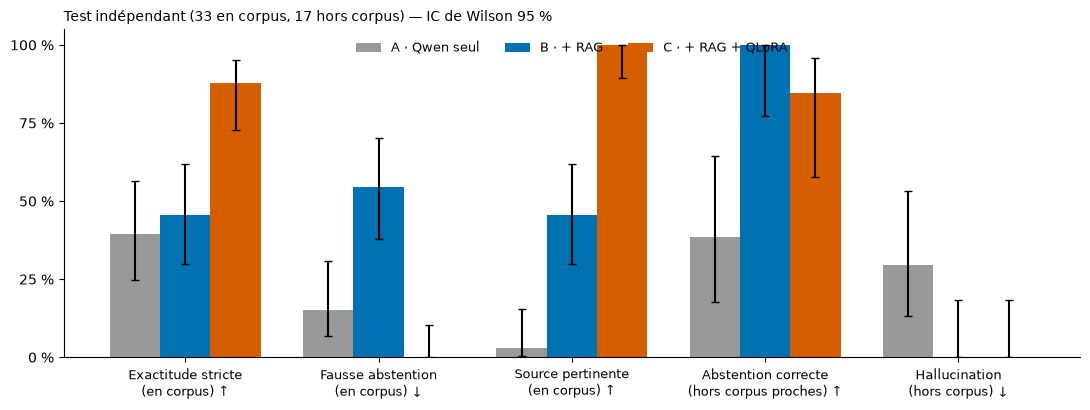

In [ ]:
import matplotlib.pyplot as plt
HEAD = [("IN | exactitude stricte (CORRECT)", "Exactitude stricte\n(en corpus) ↑"), ("IN | fausse abstention", "Fausse abstention\n(en corpus) ↓"),
        ("IN | source pertinente (fiche)", "Source pertinente\n(en corpus) ↑"), ("OOC | abstention correcte (proches)", "Abstention correcte\n(hors corpus proches) ↑"),
        ("OOC | hallucination (ASSERTED)", "Hallucination\n(hors corpus) ↓")]
COL = {"A": "#999999", "B": "#0072B2", "C": "#D55E00"}
fig, ax = plt.subplots(figsize=(11, 4.2)); w = 0.26
for j, n in enumerate(("A", "B", "C")):
    vals, errs = [], [[], []]
    for m, _ in HEAD:
        k, nn = counts(frames[n], m); lo, hi = wilson(k, nn); p = k / nn
        vals.append(p); errs[0].append(p - lo); errs[1].append(hi - p)
    ax.bar(np.arange(len(HEAD)) + (j - 1) * w, vals, w, yerr=errs, capsize=3, color=COL[n], label={"A": "A · Qwen seul", "B": "B · + RAG", "C": "C · + RAG + QLoRA"}[n])
ax.set_xticks(np.arange(len(HEAD))); ax.set_xticklabels([h for _, h in HEAD], fontsize=9)
ax.set_ylim(0, 1.05); ax.set_yticks([0, .25, .5, .75, 1]); ax.set_yticklabels(["0 %", "25 %", "50 %", "75 %", "100 %"])
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=9, loc="upper center", ncol=3)
ax.set_title("Test indépendant (33 en corpus, 17 hors corpus) — IC de Wilson 95 %", fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "fig_comparaison_ABC.png", dpi=150); plt.show()

## 14. Analyse d'erreurs

### 14.1 Taxonomie des échecs en corpus (B et C, vue système)


In [ ]:
def taxonomy(d, d_raw):
    ind = d[is_in(d)].reset_index(drop=True); raw_v = d_raw[is_in(d_raw)].reset_index(drop=True).verdict
    rows = []
    for i, r in ind.iterrows():
        if r.verdict == "CORRECT": cls = "correct"
        elif r.verdict == "PARSE_ERROR": cls = "erreur de parsing du juge"
        elif not r.rep_ctx: cls = "échec retrieval — abstention" if r.status != "answered" else "échec retrieval — réponse fausse/partielle"
        elif r.status in ("abstained_retrieval", "abstained_model"): cls = "fausse abstention"
        elif r.status == "rejected_citation": cls = "rejet de citation"
        else: cls = "échec de génération"
        rows.append(dict(id=r.id, classe=cls, source_erronée=bool(r.status == "answered" and not r.source_hit), verdict_brut=raw_v[i]))
    return pd.DataFrame(rows)

tax = {n: taxonomy(frames[n], frames[n + " brut"]) for n in ("B", "C")}
ORDER = ["correct", "échec retrieval — abstention", "échec retrieval — réponse fausse/partielle", "fausse abstention", "rejet de citation", "échec de génération", "erreur de parsing du juge"]
tax_table = pd.DataFrame({n: tax[n].classe.value_counts().reindex(ORDER, fill_value=0) for n in ("B", "C")})
tax_table.loc["(dont source erronée)"] = [int(tax[n].source_erronée.sum()) for n in ("B", "C")]
display(tax_table)
rej = {n: tax[n][tax[n].classe == "rejet de citation"] for n in ("B", "C")}
print("Rejets de citation dont la réponse brute était jugée CORRECT :", {n: int((rej[n].verdict_brut == "CORRECT").sum()) for n in rej}, "(coût de la règle de sécurité)")

,B,C
classe,,
correct,15,29
échec retrieval — abstention,0,0
échec retrieval — réponse fausse/partielle,0,0
fausse abstention,0,0
rejet de citation,18,0
échec de génération,0,4
erreur de parsing du juge,0,0
(dont source erronée),0,0


Rejets de citation dont la réponse brute était jugée CORRECT : {'B': 18, 'C': 0} (coût de la règle de sécurité)


### 14.2 Que change l'adaptateur ? Questions où C ≠ B (en corpus et hors corpus)


In [ ]:
RANK_IN = {"CORRECT": 3, "PARTIAL": 2, "ABSTAIN": 1, "INCORRECT": 0, "PARSE_ERROR": -1}
RANK_OOC = {"ABSTAIN": 2, "HEDGED": 1, "ASSERTED": 0, "PARSE_ERROR": -1}
def show_row(i, cols=("B", "C"), width=330):
    r = df_test.iloc[i]
    print(f"[{r.id}] ({r.category}) Q : {r.question}")
    if r.category == "in_corpus": print(f"    Réf : {r.gold_answer}  (fiches {r.gold_fiches}, pages {r.gold_pages}) | répondable@k = {bool(ret_df.rep_ctx[i])}")
    for n in cols:
        d = frames[n].iloc[i]
        print(f"    {n} → {d.verdict} / {d.status} | fiches {d.cited_fiches} | {textwrap.shorten(str(d.text).replace(chr(10), ' '), width)}")
    print()

better, worse = [], []
for i in range(len(df_test)):
    rk = RANK_IN if df_test.category[i] == "in_corpus" else RANK_OOC
    b, c = rk[frames["B"].verdict[i]], rk[frames["C"].verdict[i]]
    (better if c > b else worse if c < b else []).append(i)
print(f"C mieux que B : {len(better)} questions | C moins bien que B : {len(worse)} | identiques : {len(df_test) - len(better) - len(worse)}\n")
print("=" * 25, "C MIEUX QUE B", "=" * 25)
for i in better: show_row(i)
print("=" * 25, "C MOINS BIEN QUE B", "=" * 25)
for i in worse: show_row(i)

C mieux que B : 18 questions | C moins bien que B : 4 | identiques : 28

========================= C MIEUX QUE B =========================
[in01] (in_corpus) Q : Dans quel délai faut-il notifier une violation de données personnelles à la CNIL ?
    Réf : Dans les 72 heures (notification possible en deux temps : une initiale dans les 72 h, puis une complémentaire si nécessaire).  (fiches [19], pages [42]) | répondable@k = True
    B → ABSTAIN / rejected_citation | fiches [] | INFORMATION ABSENTE : les passages fournis ne contiennent pas cette information.
    C → PARTIAL / answered | fiches [19] | Dans les 72 heures, si elle présente un risque pour les droits et libertés des personnes ; en cas de risque élevé, informer les personnes concernées pour qu'elles puissent limiter les conséquences.

[in02] (in_corpus) Q : Quelle entropie minimale est exigée par défaut pour un mot de passe ?
    Réf : 80 bits (par exemple 12 caractères minimum de 4 types, ou 14 caractères minimum de 3 types san

### 14.3 Hors corpus : ce qui est répondu au lieu de s'abstenir (B et C)


In [ ]:
for n in ("B", "C"):
    d = frames[n]; idx = [i for i in range(len(d)) if d.category[i] != "in_corpus" and d.status[i] == "answered"]
    print("=" * 20, f"{n} : {len(idx)} réponses données hors corpus", "=" * 20)
    for i in idx:
        show_row(i, cols=(n,))
        for s in res[n][i]["sources"]: print(f"       source [{s['n']}] {s['citation']}")

==================== B : 0 réponses données hors corpus ====================
==================== C : 2 réponses données hors corpus ====================
[oc08] (out_corpus_near) Q : Pendant combien de temps faut-il conserver les sauvegardes ?
    C → HEDGED / answered | fiches [17] | Au moins une sauvegarde sur un site géographiquement distinct du site d'exploitation.

       source [1] Fiche 17 — Sauvegarder — Les précautions élémentaires, p. 40
[oc12] (out_corpus_near) Q : Dans quel délai faut-il informer les personnes concernées d'une violation à risque élevé ?
    C → HEDGED / answered | fiches [19] | À moins que des exceptions ne s'appliquent, dans les 72 heures après notification à la CNIL.

       source [1] Fiche 19 — Gérer les incidents et les violations — Les précautions élémentaires, p. 42


### 14.4 Échecs en corpus de la configuration C, par classe (lecture à la main)


In [ ]:
t = tax["C"]
for cls in ORDER[1:-1]:
    ids = t[t.classe == cls].id.tolist()
    if not ids: continue
    print("=" * 20, f"{cls} : {len(ids)} question(s)", "=" * 20)
    for qid in ids:
        i = int(df_test.index[df_test.id == qid][0]); show_row(i, cols=("C",))
        if res["C"][i]["status"] in ("abstained_model", "rejected_citation"):
            print("       sortie brute :", textwrap.shorten(str(res["C"][i]["raw_answer"]).replace("\n", " "), 260), "\n")

==================== échec de génération : 4 question(s) ====================
[in01] (in_corpus) Q : Dans quel délai faut-il notifier une violation de données personnelles à la CNIL ?
    Réf : Dans les 72 heures (notification possible en deux temps : une initiale dans les 72 h, puis une complémentaire si nécessaire).  (fiches [19], pages [42]) | répondable@k = True
    C → PARTIAL / answered | fiches [19] | Dans les 72 heures, si elle présente un risque pour les droits et libertés des personnes ; en cas de risque élevé, informer les personnes concernées pour qu'elles puissent limiter les conséquences.

[in03] (in_corpus) Q : Quelle entropie minimale est acceptée pour un mot de passe lorsque des mesures complémentaires de restriction d'accès sont en place ?
    Réf : 50 bits (par exemple temporisation après plusieurs échecs, Captcha ou blocage du compte après 10 échecs).  (fiches [4], pages [11]) | répondable@k = True
    C → PARTIAL / answered | fiches [4] | 50 bits, soit 8 caractères

## 15. Fiabilité du juge : annotation manuelle et accord



In [ ]:
sample = []
for n in ("A", "B", "C"):
    d = frames[n]; d = d[d.status == "answered"]
    for cat_mask, k_ in ((d.category == "in_corpus", 8), (d.category != "in_corpus", 4)):
        sub = d[cat_mask]
        sample.append(sub.sample(n=min(k_, len(sub)), random_state=SEED))
ann = pd.concat(sample)[["id", "view", "category", "question", "gold_answer", "text", "verdict"]].rename(columns={"view": "config", "text": "answer", "verdict": "judge_verdict"})
ann = ann.sample(frac=1, random_state=SEED).reset_index(drop=True)
ann["ann_id"] = range(len(ann)); ann["human_verdict"] = ""
ann[["ann_id", "judge_verdict"]].to_csv(OUTPUT_DIR / "judge_key_final.csv", index=False)           # clé du juge : à NE PAS ouvrir avant d'avoir annoté
ann.drop(columns=["judge_verdict"]).to_csv(OUTPUT_DIR / "to_annotate_final.csv", index=False)      # fichier à annoter (le verdict du juge n'y figure pas)
print(f"{len(ann)} lignes → {OUTPUT_DIR / 'to_annotate_final.csv'} (annotation en aveugle) ; remplir `human_verdict`, puis exécuter la cellule suivante")

30 lignes → outputs/step6_final/to_annotate_final.csv (annotation en aveugle) ; remplir `human_verdict`, puis exécuter la cellule suivante


In [ ]:
# À exécuter APRÈS annotation de to_annotate_final.csv (colonne human_verdict)
a = pd.read_csv(OUTPUT_DIR / "to_annotate_final.csv").merge(pd.read_csv(OUTPUT_DIR / "judge_key_final.csv"), on="ann_id").dropna(subset=["human_verdict"])
a = a[a.human_verdict.astype(str).str.strip() != ""].copy()
if len(a):
    a["h"] = a.human_verdict.astype(str).str.upper().str.strip()
    agree = float((a.h == a.judge_verdict).mean())
    labels = sorted(set(a.h) | set(a.judge_verdict)); po = agree
    pe = sum((a.h == l).mean() * (a.judge_verdict == l).mean() for l in labels)
    kappa = (po - pe) / (1 - pe) if pe < 1 else float("nan")
    print(f"Accord juge/humain : {agree:.0%} sur {len(a)} exemples | κ de Cohen = {kappa:.2f}")
    display(a.groupby("config").apply(lambda g: pd.Series({"n": len(g), "accord": (g.h == g.judge_verdict).mean()})))
    print("Désaccords :"); display(a[a.h != a.judge_verdict][["id", "config", "judge_verdict", "human_verdict"]])
    print("Repères : accord < 70 % ou κ < 0,4 → ne pas s'appuyer sur les métriques jugées ; un juge plus indulgent pour une configuration que pour une autre fausse la comparaison (voir « accord » par config).")
else:
    print("Aucune annotation manuelle pour l'instant : les métriques jugées (exactitude, hallucination) restent À CONFIRMER.")

Accord juge/humain : 60% sur 30 exemples | κ de Cohen = 0.37


,n,accord
config,,
A,12.0,0.25
B,8.0,1.00
C,10.0,0.70


Désaccords :


,id,config,judge_verdict,human_verdict
2,in18,C,CORRECT,partial
4,oc11,A,ABSTAIN,partial
5,oc03,A,HEDGED,incorrect
6,oc12,C,HEDGED,incorrect
9,in12,A,CORRECT,partial
14,oc01,A,ASSERTED,incorrect
16,in31,A,PARTIAL,incorrect
17,in11,A,CORRECT,partial
23,oc08,C,HEDGED,incorrect
25,in27,A,CORRECT,partial


Repères : accord < 70 % ou κ < 0,4 → ne pas s'appuyer sur les métriques jugées ; un juge plus indulgent pour une configuration que pour une autre fausse la comparaison (voir « accord » par config).


## 16. Sauvegarde des résultats et métadonnées de reproductibilité

In [ ]:
for n, d in frames.items():
    d.drop(columns=["key_facts"]).assign(cited_fiches=d.cited_fiches.astype(str), cited_pages=d.cited_pages.astype(str)).to_csv(OUTPUT_DIR / f"results_{n.replace(' ', '_')}.csv", index=False)
main_table.to_csv(OUTPUT_DIR / "metrics_final.csv"); paired.to_csv(OUTPUT_DIR / "paired_tests.csv", index=False)
abst_table.to_csv(OUTPUT_DIR / "abstention_breakdown.csv", index=False); tax_table.to_csv(OUTPUT_DIR / "failure_taxonomy.csv")
import torch, transformers
meta6 = {
    "step": "6_final_evaluation", "date": time.strftime("%Y-%m-%d %H:%M:%S"), "model": MODEL_ID, "test_set_sha256": TEST_SET_SHA256, "n_questions": int(len(df_test)),
    "prompt_sha256": prompt_sha, "adapter_sha256": raw_gen.adapter_sha256, "similarity_floor": FLOOR, "k": K, "retrieval": pcfg["retrieval"],
    "decoding": {"greedy": True, "max_new_tokens": MAX_NEW_TOKENS, "batch_size": BATCH_SIZE, "judge_max_new_tokens": JUDGE_MAX_NEW_TOKENS}, "enforce_citation": ENFORCE_CITATION,
    "integrity_checks": CHECKS, "generations_computed": gen.n_miss, "generations_from_log": gen.n_hit,
    "gpu": torch.cuda.get_device_name(0), "torch": torch.__version__, "transformers": transformers.__version__, "seed": SEED, "n_bootstrap": N_BOOT,
    "judge": "Qwen2.5-7B-Instruct 4-bit, adaptateur désactivé (auto-évaluation)",
}
json.dump(meta6, open(OUTPUT_DIR / "meta_step6.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False, default=str)
print("fichiers écrits dans", OUTPUT_DIR.resolve()); print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

fichiers écrits dans /content/outputs/step6_final
['.ipynb_checkpoints', 'abstention_breakdown.csv', 'failure_taxonomy.csv', 'fig_comparaison_ABC.png', 'generation_log.jsonl', 'judge_key_final.csv', 'meta_step6.json', 'metrics_final.csv', 'paired_tests.csv', 'pipeline_results_B.json', 'pipeline_results_C.json', 'results_A.csv', 'results_B.csv', 'results_B_brut.csv', 'results_C.csv', 'results_C_brut.csv', 'to_annotate_final.csv']


## 18. Synthèse (à rédiger après lecture des tableaux et du contrôle d'annotation)



In [ ]:
import os, re, json, time, shutil, hashlib, zipfile, platform
from pathlib import Path

STEP2_DIR = Path("outputs/step2_index")
STEP3_DIR = Path("outputs/step3_dataset")
STEP4_DIR = Path("outputs/step4_qlora")
STEP5_CFG = Path("outputs/step5_pipeline/pipeline_config.json")
STEP6_DIR = Path("outputs/step6_final")
BUNDLE_DIR = Path("outputs/b1_bundle")
ZIP_PATH = Path("outputs/b1_bundle.zip")
DRIVE_DIR = None            # ex. Path("/content/drive/MyDrive/b1") après drive.mount : le zip y est aussi copié (la session Colab est éphémère)
DEFAULT_CONFIG = "C"        # configuration proposée par défaut dans l'interface : "C" (avec adaptateur) ou "B" — à décider d'après les résultats de l'étape 6

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""): h.update(block)
    return h.hexdigest()

In [ ]:
assert DEFAULT_CONFIG in ("B", "C")
ADAPTER_SRC = STEP4_DIR / "adapter"
need = [STEP2_DIR / "index_config.json", STEP2_DIR / "chunks.jsonl", STEP2_DIR / "faiss.index", STEP3_DIR / "rag_prompt.json",
        STEP3_DIR / "dataset_config.json", STEP5_CFG, ADAPTER_SRC / "adapter_model.safetensors", ADAPTER_SRC / "adapter_config.json"]
missing = [str(p) for p in need if not p.exists()]
assert not missing, f"fichiers manquants : {missing}"

pcfg = json.load(open(STEP5_CFG, encoding="utf-8"))
rag_prompt = json.load(open(STEP3_DIR / "rag_prompt.json", encoding="utf-8"))
index_cfg = json.load(open(STEP2_DIR / "index_config.json", encoding="utf-8"))
adapter_cfg = json.load(open(ADAPTER_SRC / "adapter_config.json", encoding="utf-8"))

adapter_sha = sha256_file(ADAPTER_SRC / "adapter_model.safetensors")
prompt_sha = hashlib.sha256(json.dumps(rag_prompt, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
checks = [("adaptateur = celui de l'étape 5", adapter_sha == pcfg["adapter_sha256"]),
          ("prompt = celui de l'étape 5", prompt_sha == pcfg["prompt_sha256"]),
          ("k / embedder = étape 5", (index_cfg["k_final"], index_cfg["embedder"]) == (pcfg["retrieval"]["k"], pcfg["retrieval"]["embedder"]))]
m6 = STEP6_DIR / "meta_step6.json"
if m6.exists():
    meta6 = json.load(open(m6, encoding="utf-8"))
    checks += [("adaptateur = celui évalué à l'étape 6", meta6["adapter_sha256"] == adapter_sha), ("prompt = celui évalué à l'étape 6", meta6["prompt_sha256"] == prompt_sha)]
else:
    print("⚠️ étape 6 non trouvée : on ne peut pas prouver que le bundle est celui qui a été évalué.")
for name, ok in checks: print("OK    " if ok else "ÉCHEC ", name)
assert all(ok for _, ok in checks), "STOP — les artefacts ne correspondent pas à ce qui a été validé/évalué"
print("adaptateur LoRA : r =", adapter_cfg.get("r"), "| alpha =", adapter_cfg.get("lora_alpha"), "| modules =", adapter_cfg.get("target_modules"),
      "| base déclarée =", adapter_cfg.get("base_model_name_or_path"))

OK     adaptateur = celui de l'étape 5
OK     prompt = celui de l'étape 5
OK     k / embedder = étape 5
OK     adaptateur = celui évalué à l'étape 6
OK     prompt = celui évalué à l'étape 6
adaptateur LoRA : r = 16 | alpha = 16 | modules = ['gate_proj', 'k_proj', 'q_proj', 'down_proj', 'o_proj', 'v_proj', 'up_proj'] | base déclarée = unsloth/Qwen2.5-7B-Instruct-unsloth-bnb-4bit


In [ ]:
if BUNDLE_DIR.exists(): shutil.rmtree(BUNDLE_DIR)
copies = [(STEP2_DIR / "index_config.json", "step2_index"), (STEP2_DIR / "chunks.jsonl", "step2_index"), (STEP2_DIR / "faiss.index", "step2_index"),
          (STEP3_DIR / "rag_prompt.json", "step3_dataset"), (STEP3_DIR / "dataset_config.json", "step3_dataset"), (STEP5_CFG, "step5_pipeline")]
if (STEP3_DIR / "val.jsonl").exists(): copies.append((STEP3_DIR / "val.jsonl", "step3_dataset"))      # contrôle « prompt de production = prompt d'entraînement » au démarrage
for name in ("metrics_final.csv", "meta_step6.json", "paired_tests.csv"):
    if (STEP6_DIR / name).exists(): copies.append((STEP6_DIR / name, "step6_final"))
for src, sub in copies:
    (BUNDLE_DIR / sub).mkdir(parents=True, exist_ok=True); shutil.copy2(src, BUNDLE_DIR / sub / src.name)
(BUNDLE_DIR / "adapter").mkdir(parents=True, exist_ok=True)
for f in ADAPTER_SRC.iterdir():
    skip = f.name.startswith(("optimizer", "scheduler", "rng_state", "trainer_state")) or f.suffix in (".pt", ".pth")      # états d'entraînement : inutiles en production
    if f.is_file() and not skip:
        shutil.copy2(f, BUNDLE_DIR / "adapter" / f.name)

try:
    import torch, transformers, peft
    versions = dict(torch=torch.__version__, transformers=transformers.__version__, peft=peft.__version__)
except Exception:
    versions = {}
manifest = {
    "name": "B1 — Sentinelle (assistant réglementaire sourcé)", "created": time.strftime("%Y-%m-%d %H:%M:%S"), "default_config": DEFAULT_CONFIG,
    "base_model": pcfg["model"], "quantization": pcfg["quantization"], "base_model_note": "non inclus : téléchargé depuis Hugging Face au premier lancement (≈ 15 Go)",
    "adapter": {"sha256": adapter_sha, "r": adapter_cfg.get("r"), "alpha": adapter_cfg.get("lora_alpha"), "target_modules": adapter_cfg.get("target_modules"),
                "declared_base": adapter_cfg.get("base_model_name_or_path")},
    "retrieval": pcfg["retrieval"], "similarity_floor": pcfg["similarity_floor"], "prompt_sha256": prompt_sha, "decoding": pcfg["decoding"], "enforce_citation": pcfg["enforce_citation"],
    "versions_at_export": versions, "python": platform.python_version(), "evaluated_in_step6": m6.exists(),
    "files": {str(p.relative_to(BUNDLE_DIR)): sha256_file(p) for p in sorted(BUNDLE_DIR.rglob("*")) if p.is_file()},
}
json.dump(manifest, open(BUNDLE_DIR / "bundle_manifest.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
tot = sum(p.stat().st_size for p in BUNDLE_DIR.rglob("*") if p.is_file()) / 1e6
print(f"bundle : {len(manifest['files'])} fichiers, {tot:.1f} Mo → {BUNDLE_DIR.resolve()}")
for k, v in manifest["files"].items(): print(f"  {v[:10]}…  {k}")

bundle : 16 fichiers, 174.5 Mo → /content/outputs/b1_bundle
  26887c15da…  adapter/README.md
  a8534c5ab7…  adapter/adapter_config.json
  7fce6aa424…  adapter/adapter_model.safetensors
  cd8e9439f0…  adapter/chat_template.jinja
  3fd169731d…  adapter/tokenizer.json
  04b1682c59…  adapter/tokenizer_config.json
  011109acef…  step2_index/chunks.jsonl
  01fbdea6d5…  step2_index/faiss.index
  30df2d2512…  step2_index/index_config.json
  4da0160ab7…  step3_dataset/dataset_config.json
  ab7dd3eb32…  step3_dataset/rag_prompt.json
  c3377e3063…  step3_dataset/val.jsonl
  9f10620209…  step5_pipeline/pipeline_config.json
  c14f74b29d…  step6_final/meta_step6.json
  2c529580b1…  step6_final/metrics_final.csv
  aecb313a2b…  step6_final/paired_tests.csv


In [ ]:
def verify_bundle(bdir):
    man = json.load(open(Path(bdir) / "bundle_manifest.json", encoding="utf-8")); bad = []
    for rel, sha in man["files"].items():
        p = Path(bdir) / rel
        if not p.exists() or sha256_file(p) != sha: bad.append(rel)
    return bad

assert not verify_bundle(BUNDLE_DIR), verify_bundle(BUNDLE_DIR)
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(BUNDLE_DIR.rglob("*")):
        if p.is_file(): z.write(p, Path("b1_bundle") / p.relative_to(BUNDLE_DIR))
print(f"archive : {ZIP_PATH} ({ZIP_PATH.stat().st_size / 1e6:.1f} Mo) — intégrité du dossier vérifiée")
if DRIVE_DIR:
    Path(DRIVE_DIR).mkdir(parents=True, exist_ok=True); shutil.copy2(ZIP_PATH, Path(DRIVE_DIR) / ZIP_PATH.name); print("copie sur Drive :", Path(DRIVE_DIR) / ZIP_PATH.name)
try:
    from google.colab import files; files.download(str(ZIP_PATH))      # téléchargement navigateur (Colab)
except Exception:
    print("(hors Colab : récupérer l'archive à l'emplacement ci-dessus)")

archive : outputs/b1_bundle.zip (151.4 Mo) — intégrité du dossier vérifiée


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>